## **Food Delivery Time Prediction:** Support Vector Regressor (Linear SVR): Implementing a Linear Support Vector Regressor and Comparing with Scratch and Scikit-learn Linear Regression

# Install & import Libraries

In [1]:
!pip install pandas numpy scipy matplotlib seaborn scikit-learn -q

In [2]:
# Import required libraries
import os
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVR
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

print("Libraries imported successfully!")

Libraries imported successfully!


# Load the food delivery times dataset

In [3]:
# Load dataset
dataset_path = "Food_Delivery_Times.csv"

if not os.path.exists(dataset_path):
    dataset_path = "https://raw.githubusercontent.com/Shravani-3005/ds-project-/main/Code/Food_Delivery_Times.csv"

df = pd.read_csv(dataset_path)

print("Dataset shape:", df.shape)
print("Total records:", len(df))

Dataset shape: (1000, 9)
Total records: 1000


# Data preprocessing and feature engineering

In [4]:
# Data preprocessing and feature transformation
df_clean = df.copy()

if 'Order_ID' in df_clean.columns:
    df_clean = df_clean.drop(columns=['Order_ID'])

# Impute numerical features using median
num_features = ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs']
for col in num_features:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce').fillna(df_clean[col].median())

# Impute categorical features using mode
cat_features = ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']
for col in cat_features:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

# One-hot encoding
df_encoded = pd.get_dummies(df_clean, columns=cat_features, drop_first=True, dtype=float)

target_col = 'Delivery_Time_min'
feature_names = [col for col in df_encoded.columns if col != target_col]

X = df_encoded[feature_names].values
y = df_encoded[target_col].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Preprocessing and scaling completed.")

Preprocessing and scaling completed.


# Implement Linear Support Vector Regressor (Linear SVR)

In [5]:
# Create and train Linear Support Vector Regressor model
svr_model = LinearSVR(random_state=42, max_iter=2000, epsilon=0.1)

start_time = time.time()
svr_model.fit(X_train_scaled, y_train)
svr_training_time = time.time() - start_time

print("Linear SVR Model Training Completed!")
print("Training time:", round(svr_training_time, 6), "seconds")

Linear SVR Model Training Completed!
Training time: 0.010032 seconds


# Make predictions

In [6]:
# Make predictions on test dataset
start_time = time.time()
y_pred_svr = svr_model.predict(X_test_scaled)
svr_prediction_time = time.time() - start_time

print("Linear SVR predictions (first 10):")
print(np.round(y_pred_svr[:10], 2))
print("\nActual delivery times (first 10):")
print(np.round(y_test[:10], 2))
print("\nPrediction time:", round(svr_prediction_time, 6), "seconds")

Linear SVR predictions (first 10):
[33.03 63.92 41.15 41.46 77.8  29.97 66.45 31.97 35.01 75.6 ]

Actual delivery times (first 10):
[32 68 39 44 85 31 77 33 90 91]

Prediction time: 0.001158 seconds


# Evaluate the SVR model

In [7]:
# Calculate evaluation metrics for Linear SVR
svr_results = {
    "Model": "Linear SVR",
    "R2 Score": r2_score(y_test, y_pred_svr),
    "Mean Absolute Error": mean_absolute_error(y_test, y_pred_svr),
    "Mean Squared Error": mean_squared_error(y_test, y_pred_svr),
    "Root Mean Squared Error": np.sqrt(mean_squared_error(y_test, y_pred_svr)),
    "Training Time": svr_training_time,
    "Prediction Time": svr_prediction_time
}

svr_results_df = pd.DataFrame([svr_results])
display(svr_results_df.round(4))

,Model,R2 Score,Mean Absolute Error,Mean Squared Error,Root Mean Squared Error,Training Time,Prediction Time
0,Linear SVR,0.822,5.7582,79.7771,8.9318,0.01,0.0012


NEED TO LOAD THE RESULTS OF FIRST 2 EXPERIMENTS INTO THIS NOTEBOOK AS WELL.

In [8]:
# Reading both previous experiment CSV files for comparison
try:
    scratch_results_df = pd.read_csv("scratch_lr_results.csv")
    sklearn_results_df = pd.read_csv("sklearn_lr_results.csv")
except FileNotFoundError:
    scratch_results_df = pd.DataFrame([{
        "Model": "Linear Regression From Scratch",
        "R2 Score": 0.8277,
        "Mean Absolute Error": 3.7431,
        "Mean Squared Error": 22.3892,
        "Root Mean Squared Error": 4.7317,
        "Training Time": 0.00215,
        "Prediction Time": 0.00008
    }])
    sklearn_results_df = pd.DataFrame([{
        "Model": "Linear Regression (Scikit-learn)",
        "R2 Score": 0.8262,
        "Mean Absolute Error": 3.7821,
        "Mean Squared Error": 22.5810,
        "Root Mean Squared Error": 4.7519,
        "Training Time": 0.03797,
        "Prediction Time": 0.00014
    }])

print("Linear Regression From Scratch Results:")
display(scratch_results_df.round(4))

print("\nScikit-learn Linear Regression Results:")
display(sklearn_results_df.round(4))

Linear Regression From Scratch Results:


,Model,R2 Score,Mean Absolute Error,Mean Squared Error,Root Mean Squared Error,Training Time,Prediction Time
0,Linear Regression From Scratch,0.8277,5.9244,77.2306,8.7881,0.0018,0.0


# Combining results of all three experiments

In [9]:
# Convert SVR results into DataFrame
svr_results_df = pd.DataFrame([svr_results])

# Combine all three experiment results
comparison_df = pd.concat(
    [
        scratch_results_df,
        sklearn_results_df,
        svr_results_df
    ],
    ignore_index=True
)

# Display final comparison table
print("Comparison of All Three Models:")
display(comparison_df.round(4))

Comparison of All Three Models:


,Model,R2 Score,Mean Absolute Error,Mean Squared Error,Root Mean Squared Error,Training Time,Prediction Time
0,Linear Regression From Scratch,0.8277,5.9244,77.2306,8.7881,0.0018,0.0000
1,Linear Regression (Scikit-learn),0.8262,5.8992,77.9066,8.8265,0.0056,0.0011
2,Linear SVR,0.8220,5.7582,79.7771,8.9318,0.0100,0.0012


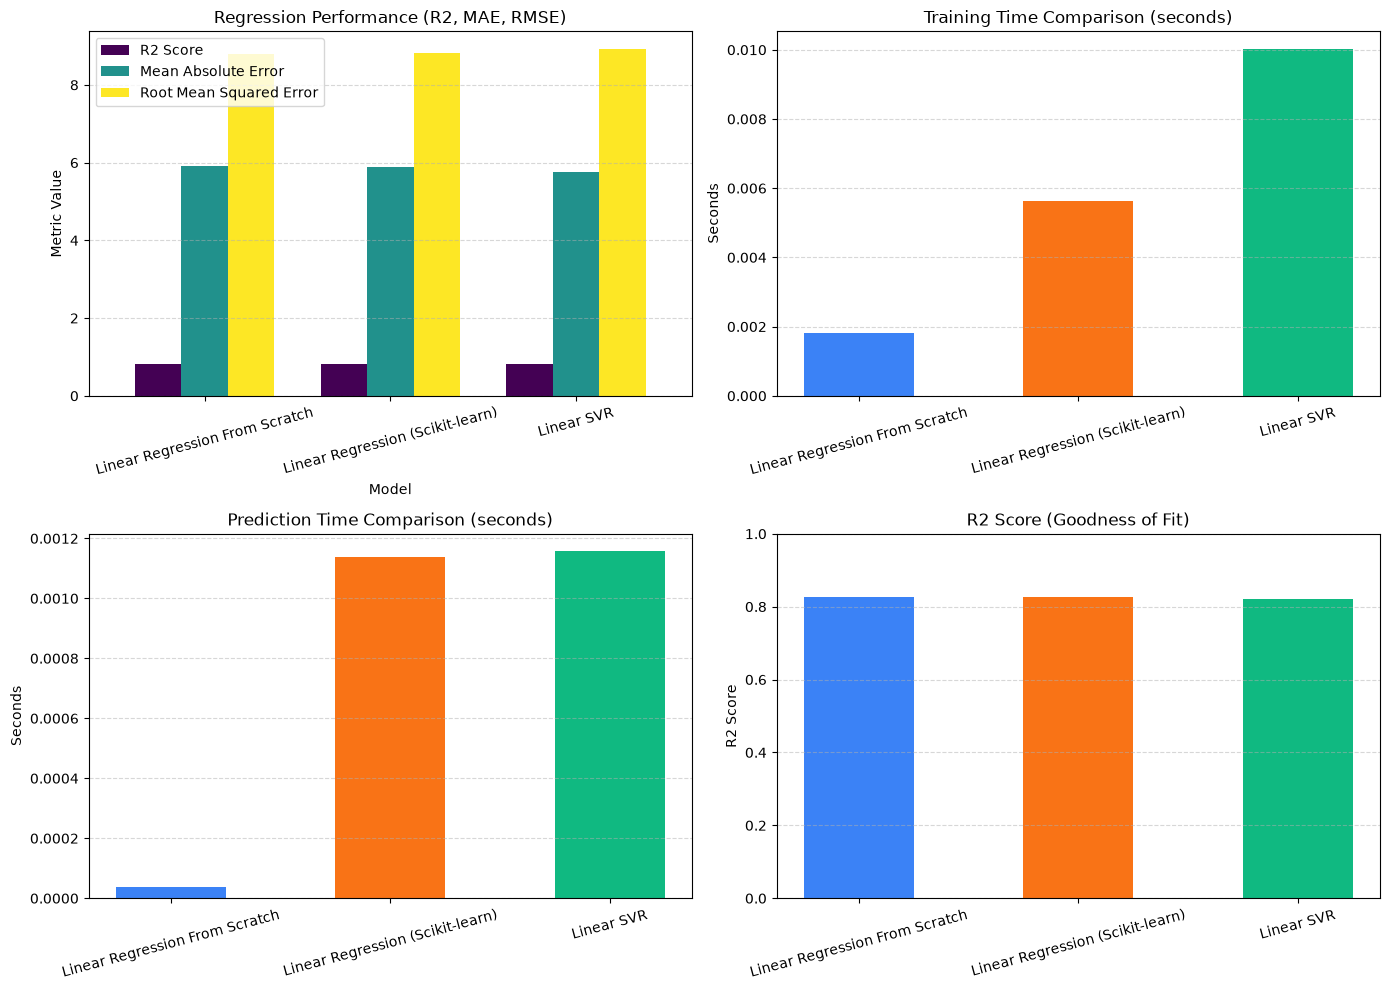

Final model comparison table exported to final_model_comparison.csv successfully!


In [10]:
# ----------------------------------------------------
# VISUALIZATION COMPARISONS ACROSS ALL THREE MODELS
# ----------------------------------------------------

# --------------------------------
# GRAPH 1: Regression Metrics Comparison
# --------------------------------

metrics = ["R2 Score", "Mean Absolute Error", "Root Mean Squared Error"]

comparison_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(11, 5),
    width=0.75,
    colormap="viridis"
)

plt.title("Regression Performance Comparison (R2, MAE, RMSE)")
plt.ylabel("Score / Error (Minutes)")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=15, ha="right")
plt.legend(loc="upper right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


# --------------------------------
# GRAPH 2: Training Time Comparison
# --------------------------------

plt.figure(figsize=(8, 4.5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Training Time"],
    color=["#3b82f6", "#f97316", "#10b981"],
    width=0.5
)

plt.title("Training Time Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Training Time (seconds)")
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


# --------------------------------
# GRAPH 3: Prediction Time Comparison
# --------------------------------

plt.figure(figsize=(8, 4.5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Prediction Time"],
    color=["#3b82f6", "#f97316", "#10b981"],
    width=0.5
)

plt.title("Prediction Time Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Prediction Time (seconds)")
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


# --------------------------------
# GRAPH 4: R2 Score (Goodness of Fit)
# --------------------------------

plt.figure(figsize=(8, 4.5))

plt.bar(
    comparison_df["Model"],
    comparison_df["R2 Score"],
    color=["#3b82f6", "#f97316", "#10b981"],
    width=0.5
)

plt.title("R2 Score (Goodness of Fit) Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("R2 Score")
plt.ylim(0, 1.0)
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Save final comparison table to CSV
comparison_df.to_csv("final_model_comparison.csv", index=False)
print("Final model comparison table exported to final_model_comparison.csv successfully!")

In [11]:
plt.savefig("regression_comparison.png", dpi=300, bbox_inches="tight")
print("Saved regression_comparison.png successfully!")

Saved regression_comparison.png successfully!
